# Running circuits on hardware

This notebook provides an introduction to running JAQSI circuits on a mock device or via the [qiclib](https://github.com/quantuminterface/qiclib) backend.

WIP so expect things to change.

The rough idea is that
1. the circuit first runs with `pulse=True` and records its pulses
2. the backend then plays the schedule from the first step for a number of shots and records one IQ point per shot and qubit
3. a discriminator then labels each point (cluster)
4. in a final `labels_to_result` this will be turned into probabilities

In [1]:
from dataclasses import replace

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

# Before importing jaqsi, so the gates run in complex128.
jax.config.update(  "jax_enable_x64", True)

import jaqsi as js
from jaqsi import Gates, noise

## Circuit -> Schedule

Generating a schedule from the circuit works by calling `.schedule` on the `Script` instance of the circuit.
Note that it requires each gate of the circuit to be instantiated with `pulse=True`.

Composite gates decompose according to their definitions.

In [2]:
from jaqsi.hardware.schedule import Sync #just for printing


def circuit(theta):
    Gates.RX(theta, wires=0, pulse=True)
    Gates.Barrier([0, 1])  # sync
    Gates.H(wires=1, pulse=True)  # RZ(π) RY(π/2)


def show(schedule):
    """Print each wire's pulses and syncs in play order."""
    for wire in range(schedule.n_qubits):
        steps = [
            f"Sync{tuple(item.wires)}"
            if isinstance(item, Sync)
            else f"{item.gate}({item.w:.3f})"
            for item in schedule.items
            if wire in item.wires
        ]
        print(f"wire {wire}: " + " → ".join(steps))


schedule = js.Script(circuit).schedule(jnp.pi / 2)
show(schedule)

wire 0: RX(1.571) → Sync(0, 1)
wire 1: Sync(0, 1) → RZ(3.142) → RY(1.571)


## Mock devices

`Mock` replays a schedule through our pulse simulation and synthesizes the readout.
Each qubit starts in its thermal state and relaxes with T1 and T2 during every pulse.
At readout, a shot in |1⟩ leaks to |2⟩ with probability `leakage`.
The shots that did not leak flip with `readout_error`.

`QubitConfig` describes a calibration as it would be used on a real device (and how it would be "guessed").
To instantiate a mock device, an additional `MockQubit` has to be defined.
This `MockQubit` is defined through properties which a real qubit would have as well.
Note that some 

Here, e.g. the qubit's resonance is at 63 MHz while we drive at 60 MHz.
We furthermore assume an amplitude scale of 0.1, while the truth is 1 / (truth.rabi_rate * guess.time_scale)=1/(1.25e9*1e-8)=0.08
Furthermore, its amplitude scale is 0.08 where we assume 0.1, so every drive pulse rotates 1.25 times too far.

In [3]:
from jaqsi.hardware.backend import QubitConfig
from jaqsi.hardware.mock import Mock, MockQubit

guess = QubitConfig(
    drive_frequency=60e6,
    amplitude_scale=0.1,
    time_scale=1e-8,
    readout_frequency=62.5e6,
    readout_amplitude=0.5,
    readout_length=400e-9,
    recording_length=400e-9,
    recording_offset=200e-9,
    reset_time=250e-6,
)
truth = MockQubit(
    frequency=63e6,
    rabi_rate=1.25e9,  # rad/s per unit device amplitude
    t1=50e-6,
    t2=50e-6,
    iq_centers=np.array([[800.0, 200.0], [-300.0, 900.0], [-900.0, -600.0]]),
    noise_width=150.0,
    thermal_population=0.15,
    leakage=0.05,
)

# Use a copy of the guess because it gets overwritten later
mock = Mock([replace(guess)], [truth], seed=0)

## Readout

Every shot ends as one IQ point per qubit.
By thermal fluctuation alone it already yields |0⟩ and some |1⟩, but hardly any leakage, since only shots in |1⟩ leak.

`calibrate_discriminator` therefore also plays RX(π) on every qubit, which moves most shots to |1⟩ (and some of those on to leakage).
It then uses k-means to cluster the points of both runs together into two or three classes.
Without labels it takes the cluster holding most of the thermal state as |0⟩, the one that RX(π) fills most as |1⟩, and a third one, if any, as leakage.
Its RX(π) uses the guessed config, so the drive has to lie within the qubit's line (about 30 MHz wide) to excite it noticeably, as it does here.

In [4]:
from jaqsi.hardware.calibration import calibrate_discriminator

#TODO: consider some more variation than "just" a pi pulse
iq_thermal, iq_excited = calibrate_discriminator(mock, shots=4000)
print("fitted centers:\n", mock.discriminator.centers[0].round())
print("true centers:\n", truth.iq_centers)

fitted centers:
 [[ 800.  199.]
 [-296.  903.]
 [-899. -609.]]
true centers:
 [[ 800.  200.]
 [-300.  900.]
 [-900. -600.]]


In [5]:
from jaqsi.hardware.discriminator import export

# Both runs, so |0⟩ and |1⟩ each have plenty of points.
iq_calibration = np.concatenate((iq_thermal, iq_excited), axis=2)
state_config = export(mock.discriminator, iq_calibration)
state_config

[(-21214318, 13599181, -2147483647)]

## Frequency and Rabi sweeps

The drive is calibrated by two sweeps (frequency and rabi).
Their results are written into `mock.qubits` defined earlier, giving a correction to the misconfigured device.

The frequency sweep plays RX(π) at drive frequencies across the qubit's line; the center of the fitted line becomes the drive frequency.
The Rabi sweep plays RX(w) over a full period and fits `c + a·sin²(k·w/2)`: an amplitude scale off by a factor `k` rotates by `k·w`, so the amplitude scale is divided by `k`.
The frequency sweep goes first, since a detuned drive also distorts the Rabi oscillation (remember: the config is written to the device).

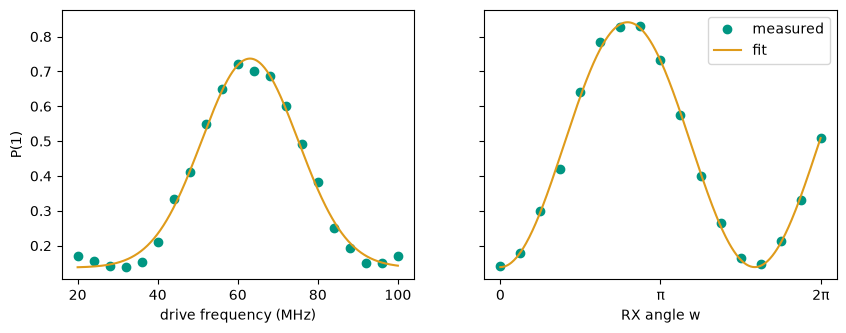

In [6]:
from jaqsi.hardware.calibration import frequency_sweep, gaussian, rabi, rabi_sweep


def plot_sweeps(frequencies, frequency_fit, angles, rabi_fit):
    """Plot both sweeps; each fit is the (p1, popt) that a sweep returns."""
    fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
    f = np.linspace(frequencies[0], frequencies[-1], 400)
    w = np.linspace(angles[0], angles[-1], 400)
    left.plot(
        frequencies / 1e6, frequency_fit[0], "o", color="#009682", label="measured"
    )
    left.plot(f / 1e6, gaussian(f, *frequency_fit[1]), color="#DF9B1B", label="fit")
    right.plot(angles, rabi_fit[0], "o", color="#009682", label="measured")
    right.plot(w, rabi(w, *rabi_fit[1]), color="#DF9B1B", label="fit")
    left.set(xlabel="drive frequency (MHz)", ylabel="P(1)")
    right.set(xlabel="RX angle w", xticks=[0, np.pi, 2 * np.pi])
    right.set_xticklabels(["0", "π", "2π"])
    right.legend()
    plt.show()


frequencies = np.linspace(20e6, 100e6, 21)
angles = np.linspace(0, 2 * np.pi, 17)
frequency_fit = frequency_sweep(mock, 0, frequencies, shots=1000)
rabi_fit = rabi_sweep(mock, 0, angles, shots=1000)
plot_sweeps(frequencies, frequency_fit, angles, rabi_fit)

The results can then be obtained from the `mock.qubits` device directly

In [7]:
calibrated = mock.qubits[0]
rows = [
    ("guess", guess.drive_frequency, guess.amplitude_scale),
    ("calibrated", calibrated.drive_frequency, calibrated.amplitude_scale),
    ("truth", truth.frequency, 1 / (truth.rabi_rate * guess.time_scale)),
]
for name, frequency, amplitude_scale in rows:
    print(
        f"{name:>10}: frequency {frequency / 1e6:6.2f} MHz, "
        f"amplitude scale {amplitude_scale:.4f}"
    )

     guess: frequency  60.00 MHz, amplitude scale 0.1000
calibrated: frequency  63.06 MHz, amplitude scale 0.0795
     truth: frequency  63.00 MHz, amplitude scale 0.0800


## Thermal state and π pulse

With the drive calibrated, RX(π) swaps the populations of the thermal state, so the |1⟩ cluster now holds most of the shots (as it should).

In the following plot, the dotted lines distinguish the clusters found by the discriminator.
The dashed line is the |0⟩/|1⟩ line that `export` found on the calibration points.
Between |0⟩ and |1⟩ the two nearly coincide.

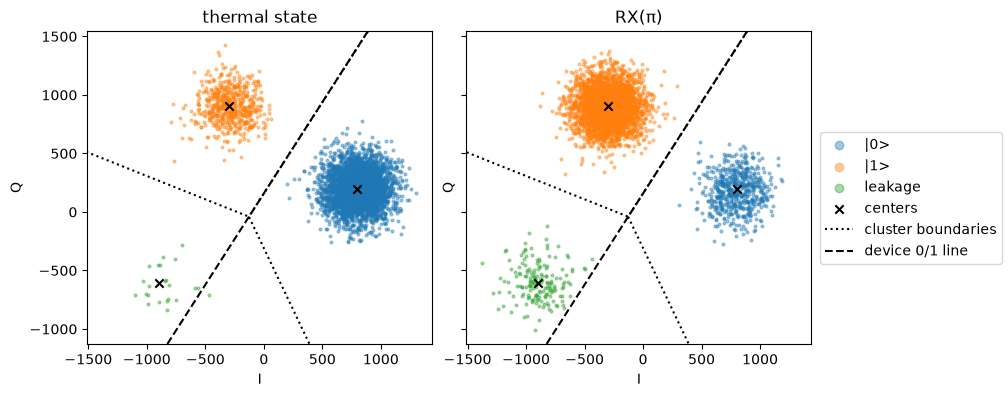

In [8]:
from matplotlib.collections import PathCollection

from jaqsi.hardware.discriminator import plot_iq


def plot_readout(discriminator, line, iq_thermal, iq_pi):
    """Plot the thermal state and RX(π) in IQ, with both kinds of boundaries."""
    fig, axes = plt.subplots(
        1, 2, figsize=(10, 4.5), sharex=True, sharey=True, layout="constrained"
    )
    for ax, iq, title in zip(axes, (iq_thermal, iq_pi), ("thermal state", "RX(π)")):
        plot_iq(iq, discriminator, ax=ax, line=line)
        ax.get_legend().remove()
        ax.set_title(title)
    handles, labels = axes[0].get_legend_handles_labels()
    legend = fig.legend(handles, labels, loc="outside right center")
    for handle in legend.legend_handles:
        if isinstance(handle, PathCollection):  # points and centers alike
            handle.set_sizes([36])
    fig.savefig("figures/backend_readout_light.png", dpi=150, transparent=True)
    plt.show()


def rx(theta):
    Gates.RX(theta, wires=0, pulse=True)


iq_pi = mock.iq(js.Script(rx).schedule(jnp.pi), shots=4000) 
plot_readout(mock.discriminator, state_config[0], iq_thermal, iq_pi)

## Running circuits

Now, given a backend, we can pass that to `Script.execute` which allows us to actually play the circuit instead of just simulating it.
We currently support `expval` and `probs` mode and now also require a `shots` argument (opposed to what is normally required in pure simulation).

In the following example, the circuit's input is the pulse parameters of the gate, i.e. for RX with the Gaussian envelope these are `[A, σ, T]` representing amplitude, width and duration.
Under the rotating-wave approximation (c.f. [[docs/pulses.md#Pulse Envelopes and Solver]]), a resonant pulse rotates by its angle times the area under its envelope.
Due to the nature of the RX gate, scaling `A` acts approximately like scaling the angle.
However, twice the duration rotates by only about 1.7π, as this mostly adds the Gaussian's tails.

Sth. that becomes immediately apparent is, that on this calibrated mock, the pulse has an overall smaller amplitude than in the simulator, because the qubit starts does not cleanly start in |0⟩ state but in its thermal state instead.

We can reproduce this behavior in simulation as well by using a `BitFlip` error prior to `RX` gate and the exact thermal population we defined for the mock qubit.

Note that `Script.execute` leaves out the leaked shots, so the number of shots might be smaller than what you would expect.
To see the leakage fraction, play a schedule with `run` and count the labels with `labels_to_result`.

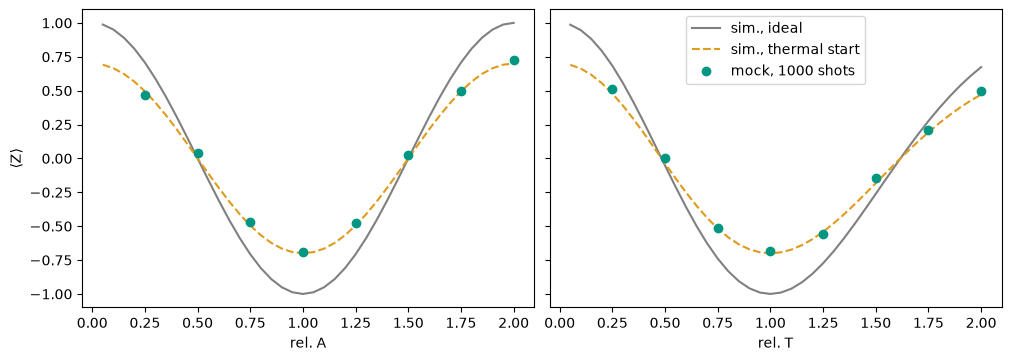

RX(π): P(1) = 0.831, leakage 4.4%


In [9]:
from jaqsi.hardware.backend import labels_to_result
from jaqsi.pulses import PulseInformation


def rx_pulse(pulse_params):
    Gates.RX(jnp.pi, wires=0, pulse=True, pulse_params=pulse_params)


def thermal_rx_pulse(pulse_params):
    noise.BitFlip(truth.thermal_population, wires=0)  # the mock's thermal state
    rx_pulse(pulse_params)


base = PulseInformation.RX.params  # [A, σ, T] of the Gaussian envelope


def scaled(index, scales):
    """The default pulse parameters, one row per scale of the one at *index*."""
    return jnp.tile(base, (len(scales), 1)).at[:, index].multiply(scales)


obs = [js.PauliZ(wires=0)]
# A zero width or duration has no lifted Gaussian, so the scales start above 0.
fine = jnp.linspace(0.05, 2, 40)
coarse = jnp.linspace(0.25, 2, 8)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True, layout="constrained")
for ax, index, name in zip(axes, (0, 2), ("A", "T")):
    ideal = js.Script(rx_pulse).execute(
        "expval", obs, args=(scaled(index, fine),), in_axes=(0,)
    )
    thermal = js.Script(thermal_rx_pulse).execute(
        "expval", obs, args=(scaled(index, fine),), in_axes=(0,)
    )
    measured = js.Script(rx_pulse, backend=mock).execute(
        "expval", obs, args=(scaled(index, coarse),), in_axes=(0,), shots=1000
    )
    ax.plot(fine, ideal, color="gray", label="sim., ideal")
    ax.plot(fine, thermal, "--", color="#DF9B1B", label="sim., thermal start")
    ax.plot(coarse, measured, "o", color="#009682", label="mock, 1000 shots")
    ax.set(xlabel=f"rel. {name}")
axes[0].set(ylabel="⟨Z⟩")
axes[1].legend()
plt.show()

labels = mock.run(js.Script(rx).schedule(jnp.pi), shots=1000)
probs, leakage = labels_to_result(labels, "probs")
print(f"RX(π): P(1) = {probs[1]:.3f}, leakage {leakage:.1%}")

### Accumulation over consecutive gates

While the previous example demonstrates the effect of thermal noise, we now move to an example where we show the effect of (fixed) T1/T2 in "deep" circuits,

Here each point runs a circuit containing $n$ identical RX($\pi$) pulses, carrying the state from one gate to the next.
The total duration now grows as $n\tau$, where $\tau$ is one pulse's duration.
We omit classical drive noise, turn of thermal noise and compare the same device parameters with finite and infinite $T_1/T_2$ to isolate relaxation and dephasing.
Ideal RX($\pi$) gates alternate between $P(1)=0$ and $1$ while the noisy sequence loses that contrast as elapsed time increases.

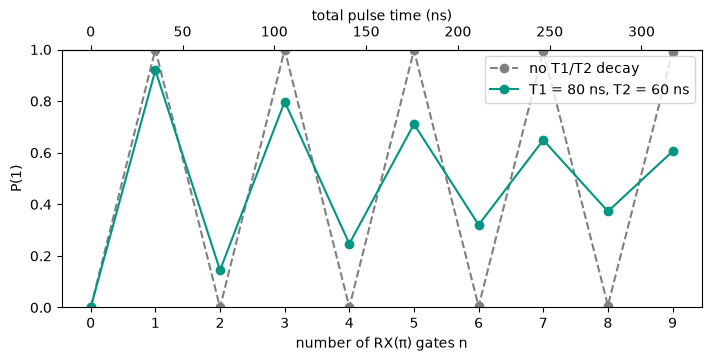

In [10]:
coherent_mock = Mock(
    [replace(calibrated)],
    [replace(truth, t1=np.inf, t2=np.inf, thermal_population=0.0)],
)
research_mock = Mock(
    [replace(calibrated)],
    [replace(truth, t1=0.5e-6, t2=0.1e-6, thermal_population=0.0)],
)

def acc_circuit(n):
    for _ in range(n):
        Gates.RX(jnp.pi, wires=0, pulse=True)

acs = js.Script(acc_circuit, n_qubits=1)
gate_counts = np.arange(10)

# create a set of growing circuits
acss = [acs.schedule(int(n)) for n in gate_counts]
acs_coherent = np.array([coherent_mock.probs(s)[1] for s in acss])
acs_damped = np.array([research_mock.probs(s)[1] for s in acss])
gate_time_ns = (
    float(acss[1].items[0].duration) * research_mock.qubits[0].time_scale * 1e9
)

fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
ax.plot(gate_counts, acs_coherent, "o--", color="gray", label="no T1/T2 decay")
ax.plot(
    gate_counts, acs_damped, "o-", color="#009682", label="T1 = 80 ns, T2 = 60 ns"
)
ax.set(xlabel="number of RX(π) gates n", ylabel="P(1)", ylim=(0, 1), xticks=gate_counts)
time_axis = ax.secondary_xaxis(
    "top", functions=(lambda n: n * gate_time_ns, lambda t: t / gate_time_ns)
)
time_axis.set_xlabel("total pulse time (ns)")
ax.legend()
fig.savefig("figures/backend_gate_sequence_light.png", dpi=150, transparent=True)
plt.show()

## Differentiable noisy pulses

So far we looked only at ideal pulses, i.e. the pulses were applied with exactly the characteristics we specified.
We can model noise during a pulse using `DriveNoise`, which is specified by an array of
- `times`: sampled times from the start of the circuit
- `amplitudes`: fractional changes in drive strength
- `phase`: rotates the axis in the quadrature plane
with the shape `(n_qubits, len(times))`.

`Mock.probs` and `Mock.density` evolve the drive and $T_1/T_2$ noise together with the Lindblad equation.
Their exact outputs support `jax.grad`, `jit` and `vmap`, without shots or a discriminator.

For example, the trace below specifies a 25% amplitude increase at 20 ns, followed by a π phase shift at 40 ns.
Between samples, both quantities are linearly interpolated, and outside the sampled interval the nearest endpoint value is retained.

We sweep the RX angle on an ideal mock, which scales the pulse amplitude while its duration stays fixed, and reuse the same noise trace at every angle.

See [backends](backend.md#mock) for the device model and [pulse evolution](pulses.md#open_system_pulse_evolution) for the solver and differentiation conventions.


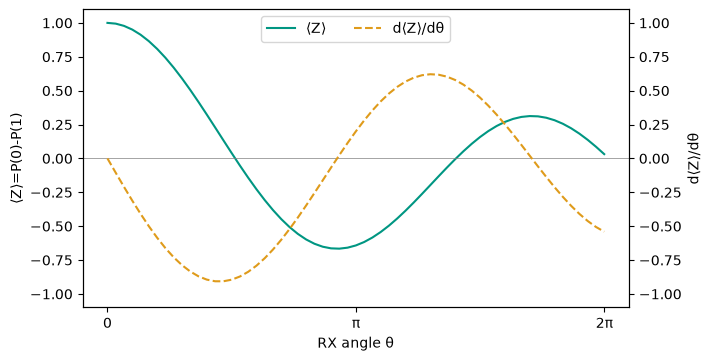

In [11]:
from jaqsi.hardware.mock import DriveNoise

research_mock = Mock(
    [replace(calibrated)],
    [replace(truth, t1=np.inf, t2=np.inf, thermal_population=0.0)],
)
drive_noise = DriveNoise(
    times=jnp.array([0.0, 20.0, 40.0]) * 1e-9,
    amplitude=jnp.array([[0.0, 0.25, 0]]),
    phase=jnp.array([[0.0, 0, np.pi]]),
)
pulse = js.Script(rx)
fine = jnp.linspace(0, 2 * jnp.pi, 61)


def z_expectation(theta):
    probs = research_mock.probs(pulse.schedule(theta), drive_noise=drive_noise)
    return probs[0] - probs[1]


z, gradient = jax.jit(jax.vmap(jax.value_and_grad(z_expectation)))(fine)

fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
gradient_axis = ax.twinx()
(state_line,) = ax.plot(fine, z, color="#009682", label="⟨Z⟩")
(gradient_line,) = gradient_axis.plot(
    fine, gradient, "--", color="#DF9B1B", label="d⟨Z⟩/dθ"
)
ax.axhline(0, color="gray", linewidth=0.5)
ax.set(
    xlabel="RX angle θ", ylabel="⟨Z⟩=P(0)-P(1)", ylim=(-1.1, 1.1), xticks=[0, np.pi, 2 * np.pi]
)
ax.set_xticklabels(["0", "π", "2π"])
gradient_axis.set(ylabel="d⟨Z⟩/dθ", ylim=(-1.1, 1.1))
ax.tick_params(axis="y")
gradient_axis.tick_params(axis="y")
ax.legend(handles=[state_line, gradient_line], loc="upper center", ncol=2)
fig.savefig("figures/backend_pulse_noise_light.png", dpi=150, transparent=True)
plt.show()


## On a QiController

We can use `QiclibBackend` (install `jaqsi[qiclib]` extra) to run the exact same schedules from above on a QiController.

Here is the job of the first section's `schedule`, which spans two wires and so needs a config per wire.
In the example below we use the calibrated one.
`job` then builds the qiclib program without a controller, allowing for a cheap check before a run.
The job itself is a single shot, which the device then repeats for every shot.
It first waits `reset_time` for the qubits to thermalize (passive reset), plays RX on wire 0, syncs both cells at the barrier, rotates the frame of wire 1 for the RZ of the H, plays its RY and reads out.
Each pulse first assigns its amplitude to its cell's variable (`v0`, `v1`), so pulses of one envelope share a pulse slot whatever their angle.
Entries like `q[0]["manip_frequency"]` are filled in from the qubit configs when the job runs.

In [12]:
from jaqsi.hardware.qiclib import QiclibBackend

print(QiclibBackend(None, [calibrated, calibrated]).job(schedule))

/home/lc3267/Documents/CodeWorkspace/jaqsi/.venv/lib/python3.12/site-packages/qiclib/packages/grpc/pimc_pb2_grpc.py:344: SyntaxWarning: invalid escape sequence '\d'
  @brief \deprecated Returns Project containing projectId, platformId and
/home/lc3267/Documents/CodeWorkspace/jaqsi/.venv/lib/python3.12/site-packages/qiclib/packages/grpc/pimc_pb2_grpc.py:361: SyntaxWarning: invalid escape sequence '\d'
  @brief \deprecated Returns buildTime in string format.
/home/lc3267/Documents/CodeWorkspace/jaqsi/.venv/lib/python3.12/site-packages/qiclib/packages/grpc/pimc_pb2_grpc.py:375: SyntaxWarning: invalid escape sequence '\d'
  @brief \deprecated Returns BoardInfo containing coreId, the Project and


QiJob:
    q = QiCells(2)
    v0 =  QiVariable()
    v1 =  QiVariable()
    Wait(q[0], q[0]["reset_time"])
    Wait(q[1], q[1]["reset_time"])
    Assign(v0, 0.055511)
    Play(q[0], QiPulse(3.521396686004318e-08, shape=Shape(0x9000), amplitude=v0, frequency=q[0]["manip_frequency"]))
    Sync(q[0], q[1])
    RotateFrame(q[1], 3.141592653589793)
    Assign(v1, 0.0560217)
    Play(q[1], QiPulse(3.488640903095614e-08, shape=Shape(0x9001), amplitude=v1, phase=1.5707963267948966, frequency=q[1]["manip_frequency"]))
    PlayReadout(q[0], QiPulse(q[0]["rec_pulse"], amplitude=q[0]["rec_amplitude"], frequency=q[0]["rec_frequency"]))
    Recording(q[0], q[0]["rec_length"], offset=q[0]["rec_offset"], save_to="0")
    PlayReadout(q[1], QiPulse(q[1]["rec_pulse"], amplitude=q[1]["rec_amplitude"], frequency=q[1]["rec_frequency"]))
    Recording(q[1], q[1]["rec_length"], offset=q[1]["rec_offset"], save_to="1")


In [13]:
RUN_ON_DEVICE = False  # True only with a QiController on the network

if RUN_ON_DEVICE:
    from qiclib import QiController

    # Replace the guess by your qubit's settings and the address by your
    # controller's.
    device = QiclibBackend(QiController("192.0.2.1"), [replace(guess)])
    iq_thermal, iq_excited = calibrate_discriminator(device, shots=4000)
    iq_calibration = np.concatenate((iq_thermal, iq_excited), axis=2)
    device.write_state_config(iq_calibration)

In [14]:
if RUN_ON_DEVICE:
    # Sweep around your qubit's intermediate frequency.
    frequency_fit = frequency_sweep(device, 0, frequencies, shots=1000)
    rabi_fit = rabi_sweep(device, 0, angles, shots=1000)
    plot_sweeps(frequencies, frequency_fit, angles, rabi_fit)
    print(device.qubits[0])

In [15]:
if RUN_ON_DEVICE:
    device.active_reset = True  # optional
    iq_pi = device.iq(js.Script(rx).schedule(jnp.pi), shots=4000)
    line = export(device.discriminator, iq_calibration)[0]
    plot_readout(device.discriminator, line, iq_thermal, iq_pi)